Recomendação de Cursos Online para Desenvolvimento
Profissional: uma Aplicação de Filtragem Colaborativa e
Baseada em Conteúdo

**Projeto Aplicado III — Universidade Presbiteriana Mackenzie**

Bruno Cerqueira Gianotti | Reginaldo Rogério de Campos | Samya Camily de Santana Silva

---

Este notebook reúne, em ordem, todo o pipeline técnico do projeto:

1. Análise Exploratória de Dados (EDA)
2. Limpeza e Pré-processamento
3. Modelo Content-Based (TF-IDF + similaridade de cosseno)
4. Modelo Colaborativo (KNN item-based)
5. Avaliação comparativa (Precision@K, Recall@K)
6. Modelo Híbrido (combinação ponderada dos dois modelos)

**Base de dados:** [Course Reviews on Coursera](https://www.kaggle.com/datasets/imuhammad/course-reviews-on-coursera) (Kaggle)


> **Versão 3 (Etapa 3, outubro de 2026).** Parte da versão 2 do grupo, que corrigiu a forma de medir (perfil de texto só com o treino, baseline por número de avaliações, mesma amostra para todos, normalização depois de tirar os cursos já feitos) e fez a varredura do α. Nesta versão:
> - **Seção 8 (nova):** escolha da configuração em uma **validação separada**, sem olhar o teste; teste de **n-gramas** no TF-IDF e de **mais vizinhos** no KNN; novas métricas **NDCG@K** e **K = 10**; avaliação final **uma única vez** no teste e teste de significância (bootstrap).
> - Removida a célula de imports duplicada; corrigida a mensagem do pré-processamento, que dizia salvar arquivos que não eram salvos; a seção 6 não duplica mais a linha do Híbrido no CSV.

## 0. Configuração do ambiente

In [1]:
# Bibliotecas Python utilizadas

!pip install -q pandas numpy scikit-learn scipy kagglehub
import os
import pickle
import pandas as pd
import numpy as np
import kagglehub

from scipy.sparse import csr_matrix
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.neighbors import NearestNeighbors


/usr/local/lib/python3.11/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 0.1 Carregar os dados

Este notebook tenta **3 formas** de obter os dados, nesta ordem:

1. **Download automático do Kaggle** (via `kagglehub`) — não precisa fazer upload manual,
   mas exige uma credencial de API do Kaggle configurada (ver como obter abaixo).
2. **Upload manual** (se a opção 1 falhar) — sobe os dois CSVs pela interface do Colab.
   💡 **Dica:** o `Coursera_reviews.csv` tem ~260 MB, o que deixa o upload bem lento.
   Comprima-o em **gzip** antes de subir (gera um `Coursera_reviews.csv.gz` de ~33 MB) —
   o notebook aceita o arquivo comprimido do mesmo jeito, sem precisar descompactar.
   No Windows, o 7-Zip faz isso (`Add to archive` → formato `gzip`); no Mac/Linux, o
   comando `gzip -k Coursera_reviews.csv` no terminal.
3. **Arquivos locais** — se você já tiver os CSVs (ou `.csv.gz`) na mesma pasta do notebook.

### Como obter a credencial do Kaggle (só precisa fazer uma vez)

1. Acesse https://www.kaggle.com/settings → seção **API** → botão **Create New Token**.
2. Isso baixa um arquivo `kaggle.json` pro seu computador.
3. No Colab, vá no ícone de **chave 🔑** (Secrets) na barra lateral esquerda e crie dois
   secrets: `KAGGLE_USERNAME` e `KAGGLE_KEY`, com os valores que estão dentro do `kaggle.json`
   (abra o arquivo num editor de texto pra ver — são só duas linhas).
4. Ative o acesso do notebook a esses secrets (toggle "Notebook access").

Se você pular essa configuração, sem problema — o notebook detecta e pede upload manual
automaticamente.


In [2]:
import os

def localizar_csvs(pasta):
    """Procura recursivamente os arquivos necessarios dentro de uma pasta
    (o kagglehub baixa o dataset numa estrutura de subpastas que pode variar).
    Aceita tanto .csv quanto .csv.gz (arquivo comprimido -- o pandas le os
    dois formatos exatamente do mesmo jeito, sem precisar descompactar)."""
    alvos = {
        "Coursera_courses.csv": ("Coursera_courses.csv", "Coursera_courses.csv.gz"),
        "Coursera_reviews.csv": ("Coursera_reviews.csv", "Coursera_reviews.csv.gz"),
    }
    encontrados = {}
    for raiz, _, arquivos in os.walk(pasta):
        for arq in arquivos:
            for chave, nomes_aceitos in alvos.items():
                if arq in nomes_aceitos and chave not in encontrados:
                    encontrados[chave] = os.path.join(raiz, arq)
    return encontrados

caminhos = {}

# -------------------------------------------------------------
# Opcao 1: baixar direto do Kaggle via kagglehub (recomendado --
# elimina o upload manual). So funciona se houver credencial
# configurada (variaveis de ambiente KAGGLE_USERNAME/KAGGLE_KEY,
# arquivo ~/.kaggle/kaggle.json, ou secrets do Colab).
# -------------------------------------------------------------
try:
    import kagglehub

    # No Colab, tenta carregar as credenciais dos "Secrets" (icone de chave)
    try:
        from google.colab import userdata
        os.environ["KAGGLE_USERNAME"] = userdata.get("KAGGLE_USERNAME")
        os.environ["KAGGLE_KEY"] = userdata.get("KAGGLE_KEY")
    except Exception:
        pass  # nao esta no Colab, ou secrets nao configurados -- tenta mesmo assim

    print("Tentando baixar o dataset direto do Kaggle...")
    pasta_kaggle = kagglehub.dataset_download("imuhammad/course-reviews-on-coursera")
    caminhos = localizar_csvs(pasta_kaggle)
    if len(caminhos) == 2:
        print("Dataset baixado automaticamente em:", pasta_kaggle)
except Exception as e:
    print(f"Nao foi possivel baixar automaticamente ({type(e).__name__}: {e}).")
    print("Seguindo para upload manual...")

# -------------------------------------------------------------
# Opcao 2: upload manual (fallback, caso a Opcao 1 nao funcione)
# -------------------------------------------------------------
if len(caminhos) < 2:
    try:
        import google.colab
        from google.colab import files
        print("\nFaca upload dos arquivos (aceita .csv ou .csv.gz comprimido):")
        uploaded = files.upload()
        caminhos.update(localizar_csvs("."))
    except ImportError:
        pass  # nao esta no Colab -- tenta Opcao 3 abaixo

# -------------------------------------------------------------
# Opcao 3: arquivos ja presentes na pasta local do notebook
# -------------------------------------------------------------
if len(caminhos) < 2:
    caminhos.update(localizar_csvs("."))

# Confirma que os dois arquivos foram localizados por algum dos metodos acima
assert "Coursera_courses.csv" in caminhos, "Coursera_courses.csv nao encontrado (todas as opcoes falharam)"
assert "Coursera_reviews.csv" in caminhos, "Coursera_reviews.csv nao encontrado (todas as opcoes falharam)"

CAMINHO_COURSES = caminhos["Coursera_courses.csv"]
CAMINHO_REVIEWS = caminhos["Coursera_reviews.csv"]
DATA_DIR = ""  # pasta atual -- usada para salvar os modelos (.pkl) gerados nos proximos passos
print("\nArquivos prontos para uso:")
print(" - courses:", CAMINHO_COURSES)
print(" - reviews:", CAMINHO_REVIEWS)


Tentando baixar o dataset direto do Kaggle...


Nao foi possivel baixar automaticamente (ProxyError: HTTPSConnectionPool(host='api.kaggle.com', port=443): Max retries exceeded with url: /v1/datasets.DatasetApiService/GetDataset (Caused by ProxyError('Unable to connect to proxy', OSError('Tunnel connection failed: 403 Forbidden')))).
Seguindo para upload manual...

Arquivos prontos para uso:
 - courses: ./Coursera_courses.csv
 - reviews: ./Coursera_reviews.csv


## 1. Análise Exploratória de Dados (EDA)

Objetivo: entender a estrutura dos dados antes de mexer em qualquer modelo — tamanho das
tabelas, valores nulos, duplicatas, distribuição das notas e esparsidade da matriz usuário-item.


In [3]:
import pandas as pd

# -------------------------------------------------------------
# 1. Carregar os dados
# -------------------------------------------------------------
# 'courses' = tabela de ITENS (os cursos)
# 'reviews' = tabela de INTERACOES (usuario avaliou curso com nota X)
courses = pd.read_csv(CAMINHO_COURSES)
reviews = pd.read_csv(CAMINHO_REVIEWS)

print("=" * 60)
print("1. TAMANHO DAS TABELAS")
print("=" * 60)
print(f"Cursos (itens):        {courses.shape[0]:,} linhas | {courses.shape[1]} colunas")
print(f"Reviews (interacoes):  {reviews.shape[0]:,} linhas | {reviews.shape[1]} colunas")

# -------------------------------------------------------------
# 2. Ver as colunas e os primeiros registros
# -------------------------------------------------------------
print("\n" + "=" * 60)
print("2. COLUNAS")
print("=" * 60)
print("courses:", list(courses.columns))
print("reviews:", list(reviews.columns))

# -------------------------------------------------------------
# 3. Checar valores nulos (dados faltando)
# -------------------------------------------------------------
# Isso e importante: se tiver muito nulo em uma coluna-chave
# (ex: rating ou course_id), precisamos tratar antes de seguir.
print("\n" + "=" * 60)
print("3. VALORES NULOS")
print("=" * 60)
print("courses:\n", courses.isnull().sum())
print("\nreviews:\n", reviews.isnull().sum())

# -------------------------------------------------------------
# 4. Checar duplicatas
# -------------------------------------------------------------
print("\n" + "=" * 60)
print("4. LINHAS DUPLICADAS")
print("=" * 60)
print(f"courses: {courses.duplicated().sum()} duplicadas")
print(f"reviews: {reviews.duplicated().sum()} duplicadas")

# -------------------------------------------------------------
# 5. Distribuicao das notas (ratings)
# -------------------------------------------------------------
# Ponto de atencao que ja discutimos antes: plataformas de curso
# tendem a ter nota concentrada em 4-5 estrelas (vies de quem
# responde review geralmente esta satisfeito).
print("\n" + "=" * 60)
print("5. DISTRIBUICAO DAS NOTAS (RATING)")
print("=" * 60)
print(reviews["rating"].value_counts().sort_index())
print(f"\nMedia geral das notas: {reviews['rating'].mean():.2f}")

# -------------------------------------------------------------
# 6. Quantas avaliacoes cada USUARIO fez (esparsidade)
# -------------------------------------------------------------
# Isso importa muito pra filtragem colaborativa: se cada usuario
# avaliou so 1 curso, fica dificil achar "usuarios parecidos".
avaliacoes_por_usuario = reviews.groupby("reviewers").size()
print("\n" + "=" * 60)
print("6. AVALIACOES POR USUARIO")
print("=" * 60)
print(f"Numero de usuarios unicos: {avaliacoes_por_usuario.shape[0]:,}")
print(f"Media de avaliacoes por usuario: {avaliacoes_por_usuario.mean():.2f}")
# ATENCAO: este percentual e da base BRUTA (antes de remover as duplicatas).
# O valor apos a limpeza (cerca de 72%) e calculado no final da secao 2.
print(f"Usuarios com apenas 1 avaliacao: {(avaliacoes_por_usuario == 1).sum():,} "
      f"({(avaliacoes_por_usuario == 1).mean() * 100:.1f}%)")
print(f"Usuarios com 5+ avaliacoes: {(avaliacoes_por_usuario >= 5).sum():,}")

# -------------------------------------------------------------
# 7. Quantas avaliacoes cada CURSO tem
# -------------------------------------------------------------
avaliacoes_por_curso = reviews.groupby("course_id").size()
print("\n" + "=" * 60)
print("7. AVALIACOES POR CURSO")
print("=" * 60)
print(f"Numero de cursos com pelo menos 1 review: {avaliacoes_por_curso.shape[0]:,}")
print(f"Media de avaliacoes por curso: {avaliacoes_por_curso.mean():.1f}")
print("\nTop 5 cursos com mais avaliacoes:")
print(avaliacoes_por_curso.sort_values(ascending=False).head(5))

# -------------------------------------------------------------
# 8. Todo course_id de reviews existe na tabela de cursos?
# -------------------------------------------------------------
# Se houver review de um curso que nao esta na tabela "courses",
# precisamos decidir o que fazer com isso no pre-processamento.
ids_reviews = set(reviews["course_id"].unique())
ids_courses = set(courses["course_id"].unique())
orfaos = ids_reviews - ids_courses
print("\n" + "=" * 60)
print("8. CONSISTENCIA ENTRE TABELAS")
print("=" * 60)
print(f"course_ids em reviews mas ausentes em courses: {len(orfaos)}")

print("\nEDA concluida.")

1. TAMANHO DAS TABELAS
Cursos (itens):        623 linhas | 4 colunas
Reviews (interacoes):  1,454,711 linhas | 5 colunas

2. COLUNAS
courses: ['name', 'institution', 'course_url', 'course_id']
reviews: ['reviews', 'reviewers', 'date_reviews', 'rating', 'course_id']

3. VALORES NULOS
courses:
 name           0
institution    0
course_url     0
course_id      0
dtype: int64

reviews:
 reviews         153
reviewers         0
date_reviews      0
rating            0
course_id         0
dtype: int64

4. LINHAS DUPLICADAS
courses: 0 duplicadas


reviews: 934764 duplicadas

5. DISTRIBUICAO DAS NOTAS (RATING)
rating
1      17354
2      16188
3      48303
4     226702
5    1146164
Name: count, dtype: int64

Media geral das notas: 4.70



6. AVALIACOES POR USUARIO
Numero de usuarios unicos: 287,808
Media de avaliacoes por usuario: 5.05
Usuarios com apenas 1 avaliacao: 23,647 (8.2%)
Usuarios com 5+ avaliacoes: 70,467

7. AVALIACOES POR CURSO
Numero de cursos com pelo menos 1 review: 604
Media de avaliacoes por curso: 2408.5

Top 5 cursos com mais avaliacoes:
course_id
python                            45218
machine-learning                  35895
neural-networks-deep-learning     35750
technical-support-fundamentals    35319
python-data                       33546
dtype: int64

8. CONSISTENCIA ENTRE TABELAS
course_ids em reviews mas ausentes em courses: 0

EDA concluida.


## 2. Limpeza e Pré-processamento

Remoção de duplicatas (achamos ~64% de linhas duplicadas no EDA), tratamento de nulos,
criação do "perfil textual" de cada curso (agregando suas próprias reviews, já que a base
não possui coluna de descrição) e divisão treino/teste 80/20 por usuário.


In [4]:
import pandas as pd

# -------------------------------------------------------------
# 1. Carregar os dados originais
# -------------------------------------------------------------
courses = pd.read_csv(CAMINHO_COURSES)
reviews = pd.read_csv(CAMINHO_REVIEWS)

print(f"Antes da limpeza: {reviews.shape[0]:,} reviews")

# -------------------------------------------------------------
# 2. Remover duplicatas exatas
# -------------------------------------------------------------
# No EDA vimos que a mesma review (mesmo texto, usuario, curso,
# data e nota) aparecia repetida 2-3x -- provavelmente um
# artefato do processo de coleta (scraping). Remover para nao
# distorcer o peso de usuarios/cursos no modelo.
reviews = reviews.drop_duplicates()
print(f"Depois de remover duplicatas: {reviews.shape[0]:,} reviews")

# -------------------------------------------------------------
# 3. Tratar valores nulos
# -------------------------------------------------------------
# So 153 reviews sem texto -- decidimos descartar, ja que sao
# poucas e o texto e essencial pro modelo Content-Based.
antes = reviews.shape[0]
reviews = reviews.dropna(subset=["reviews"])
print(f"Removidas {antes - reviews.shape[0]} reviews sem texto")

# -------------------------------------------------------------
# 4. Limpar o nome do reviewer
# -------------------------------------------------------------
# Os nomes vem no formato "By \t Nome Sobrenome" -- vamos tirar
# o prefixo "By" e espacos/tabs extras, pra ficar so o nome.
reviews["reviewers"] = (
    reviews["reviewers"]
    .str.replace(r"^By\s*", "", regex=True)  # remove "By " do inicio
    .str.replace(r"\s+", " ", regex=True)     # colapsa espacos/tabs multiplos
    .str.strip()
)

# -------------------------------------------------------------
# 5. Converter a data para formato datetime
# -------------------------------------------------------------
reviews["date_reviews"] = pd.to_datetime(reviews["date_reviews"], format="%b %d, %Y")

# -------------------------------------------------------------
# 6. Criar um ID numerico para cada usuario
# -------------------------------------------------------------
# Motivo: nomes de reviewer podem se repetir entre pessoas
# diferentes (ex: dois "John Smith"). Isso e uma limitacao
# conhecida do dataset (nao ha ID unico de usuario, so o nome
# que a pessoa digitou). Vamos documentar isso no relatorio
# como uma limitacao dos dados.
# Criamos um ID interno so pra facilitar o processamento.
reviews["user_id"] = reviews["reviewers"].astype("category").cat.codes


# -------------------------------------------------------------
# 7. Split treino/teste (80/20 por usuario)
# -------------------------------------------------------------
# Importante: NAO e um split aleatorio simples em cima de todas
# as linhas. Fazemos por usuario, pra garantir que todo usuario
# tenha pelo menos uma interacao no treino E no teste (senao a
# gente nao consegue avaliar recomendacao pra ele).
# Ordenamos por data e pegamos os ultimos 20% de cada usuario
# pro teste -- isso simula "prever o futuro" com base no passado,
# que e mais realista do que embaralhar aleatoriamente.

reviews = reviews.sort_values(["user_id", "date_reviews"]).reset_index(drop=True)

# Posicao de cada review dentro do historico do seu usuario (0, 1, 2...)
posicao_no_grupo = reviews.groupby("user_id").cumcount()
# Tamanho total do historico daquele usuario
tamanho_grupo = reviews.groupby("user_id")["user_id"].transform("size")
# Ponto de corte: 80% do historico de cada usuario (minimo 1 review no treino)
corte = (tamanho_grupo * 0.8).astype(int).clip(lower=1)

reviews["conjunto"] = "treino"
reviews.loc[posicao_no_grupo >= corte, "conjunto"] = "teste"

print("\nDistribuicao do split:")
print(reviews["conjunto"].value_counts())

# Usuarios com so 1 review inteira caem 100% no treino (nao tem
# como testar neles) -- isso e esperado e sera discutido como
# limitacao (problema de cold-start).

# -------------------------------------------------------------
# 8. Perfil de conteudo dos cursos (SO COM O TREINO)
# -------------------------------------------------------------
treino_tmp = reviews[reviews["conjunto"] == "treino"]

perfil_conteudo = (
    treino_tmp.groupby("course_id")["reviews"]
    .apply(" ".join)
    .reset_index(name="conteudo_textual")
)

courses = (
    courses.drop(columns="conteudo_textual", errors="ignore")
           .merge(perfil_conteudo, on="course_id", how="left")
)

sem_review = courses["conteudo_textual"].isnull().sum()
print(f"\nCursos sem nenhuma review no TREINO (sem conteudo textual): {sem_review}")
courses["conteudo_textual"] = courses["conteudo_textual"].fillna(courses["name"])

# -------------------------------------------------------------
# 9. Salvar os dados limpos para os proximos passos
# -------------------------------------------------------------
# Os DataFrames "reviews" e "courses" ja ficam disponiveis em memoria
# para as proximas celulas deste notebook (nao precisamos salvar em CSV aqui).

print("\nDados limpos prontos em memória (DataFrames reviews e courses).")
print("\nPre-processamento concluido.")

Antes da limpeza: 1,454,711 reviews


Depois de remover duplicatas: 519,947 reviews
Removidas 61 reviews sem texto



Distribuicao do split:
conjunto
treino    419841
teste     100045
Name: count, dtype: int64



Cursos sem nenhuma review no TREINO (sem conteudo textual): 19

Dados limpos prontos em memória (DataFrames reviews e courses).

Pre-processamento concluido.


In [5]:
por_usuario = reviews.groupby("user_id").size()
print(f"Usuarios unicos (apos limpeza): {len(por_usuario):,}")
print(f"Usuarios com apenas 1 avaliacao: {(por_usuario == 1).sum():,} ({(por_usuario == 1).mean():.1%})")

Usuarios unicos (apos limpeza): 283,024
Usuarios com apenas 1 avaliacao: 205,180 (72.5%)


## 3. Modelo Content-Based (TF-IDF)

Vetorização do conteúdo textual de cada curso via TF-IDF e cálculo de similaridade de
cosseno entre todos os pares de cursos. Recomendação = cursos mais parecidos com os que o
usuário avaliou bem (rating ≥ 4) no treino.


In [6]:
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# -------------------------------------------------------------
# 1. Carregar os dados ja limpos (saida do Passo 2)
# -------------------------------------------------------------
# "courses" e "reviews" ja foram criados e limpos no Passo 2
# Separar treino e teste (coluna criada no Passo 2)
treino = reviews[reviews["conjunto"] == "treino"]
teste = reviews[reviews["conjunto"] == "teste"]

# -------------------------------------------------------------
# 2. Vetorizar o conteudo textual dos cursos com TF-IDF
# -------------------------------------------------------------
# TF-IDF (Term Frequency - Inverse Document Frequency) da mais
# peso pra palavras que aparecem MUITO em um curso especifico,
# mas POUCO nos outros cursos -- ou seja, palavras que realmente
# identificam o assunto daquele curso.
#
# stop_words="english": remove palavras sem valor semantico
#   (the, is, a, and...) -- as reviews estao em ingles.
# max_features=5000: limita o vocabulario as 5000 palavras mais
#   relevantes, pra nao pesar demais o processamento.
# min_df=2: ignora palavras que aparecem em menos de 2 cursos
#   (normalmente erros de digitacao ou nomes proprios raros).
vectorizer = TfidfVectorizer(
    stop_words="english",
    max_features=5000,
    min_df=2,
)

matriz_tfidf = vectorizer.fit_transform(courses["conteudo_textual"])
print(f"Matriz TF-IDF: {matriz_tfidf.shape[0]} cursos x {matriz_tfidf.shape[1]} termos")

# -------------------------------------------------------------
# 3. Calcular a similaridade entre TODOS os pares de cursos
# -------------------------------------------------------------
# similaridade_cosseno[i][j] = o quao parecido o curso i e do
# curso j (varia de 0 = nada parecido, a 1 = identico).
similaridade = cosine_similarity(matriz_tfidf)

# Colocamos em um DataFrame pra facilitar consultar por course_id
sim_df = pd.DataFrame(
    similaridade,
    index=courses["course_id"],
    columns=courses["course_id"],
)

# -------------------------------------------------------------
# 4. Funcao que recomenda cursos pra um usuario
# -------------------------------------------------------------
def recomendar_content_based(user_id, top_k=5):
    """
    Recomenda 'top_k' cursos para o usuario, baseado nos cursos
    que ele avaliou bem (rating >= 4) no conjunto de TREINO.
    """
    # Cursos que esse usuario avaliou bem no treino
    avaliados_bem = treino[
        (treino["user_id"] == user_id) & (treino["rating"] >= 4)
    ]["course_id"].unique()

    if len(avaliados_bem) == 0:
        return []  # sem historico positivo, nao da pra recomendar por conteudo

    # Cursos que o usuario ja fez (treino + teste), pra nao recomendar de novo
    ja_fez = set(treino[treino["user_id"] == user_id]["course_id"].unique())

    # Somamos a similaridade dos cursos candidatos com TODOS os
    # cursos que o usuario avaliou bem -- cursos parecidos com
    # varios dos que ele gostou pontuam mais alto.
    score_candidatos = sim_df[avaliados_bem].sum(axis=1)

    # Removemos os cursos que ele ja fez
    score_candidatos = score_candidatos.drop(labels=ja_fez, errors="ignore")

    # Pegamos os top_k com maior score
    top_cursos = score_candidatos.sort_values(ascending=False).head(top_k)

    return list(top_cursos.index)


# -------------------------------------------------------------
# 5. Teste manual (sanity check) -- vamos conferir se as
#    recomendacoes fazem sentido pra um usuario real
# -------------------------------------------------------------
# Pegamos um usuario "tipico": nem quem so avaliou 1 curso, nem
# um outlier com centenas de avaliacoes (que dilui o sinal e
# dificulta interpretar visualmente se a recomendacao faz sentido).
# Escolhemos alguem com um historico moderado, entre 3 e 8 cursos.
contagem = treino[treino["rating"] >= 4]["user_id"].value_counts()
candidatos = contagem[(contagem >= 3) & (contagem <= 8)]
usuario_exemplo = candidatos.index[0]

cursos_que_gostou = treino[
    (treino["user_id"] == usuario_exemplo) & (treino["rating"] >= 4)
]["course_id"].tolist()

nomes_cursos_que_gostou = courses[
    courses["course_id"].isin(cursos_que_gostou)
]["name"].tolist()

recomendados = recomendar_content_based(usuario_exemplo, top_k=5)
nomes_recomendados = courses[courses["course_id"].isin(recomendados)]["name"].tolist()

print("\n" + "=" * 60)
print("TESTE MANUAL DE SANIDADE (Content-Based)")
print("=" * 60)
print(f"Usuario: {usuario_exemplo}")
print(f"\nCursos que ele avaliou bem (treino): {nomes_cursos_que_gostou}")
print(f"\nCursos RECOMENDADOS pelo modelo: {nomes_recomendados}")

# -------------------------------------------------------------
# 6. Salvar a matriz de similaridade e o vectorizer, pra usar
#    depois na etapa de avaliacao (Passo 5)
# -------------------------------------------------------------
import pickle

with open(DATA_DIR + "content_based_model.pkl", "wb") as f:
    pickle.dump({"sim_df": sim_df}, f)

print("\nModelo Content-Based salvo em content_based_model.pkl")

Matriz TF-IDF: 623 cursos x 5000 termos



TESTE MANUAL DE SANIDADE (Content-Based)
Usuario: 1009

Cursos que ele avaliou bem (treino): ['What is Data Science?', 'Python for Data Science and AI', 'Finance for Non-Finance Professionals', 'AWS Fundamentals: Going Cloud-Native', 'Introduction to Artificial Intelligence (AI)', 'FinTech: Foundations, Payments, and Regulations', 'AWS Fundamentals: Addressing Security Risk', 'Cryptocurrency and Blockchain: An Introduction to Digital Currencies']

Cursos RECOMENDADOS pelo modelo: ['Technical Support Fundamentals', 'The Data Scientist’s Toolbox', 'Data Analysis with Python', 'Autodesk Certified Professional: AutoCAD for Design and Drafting Exam Prep', 'C for Everyone: Programming Fundamentals']

Modelo Content-Based salvo em content_based_model.pkl


## 4. Modelo Colaborativo (KNN Item-Based)

Constrói a matriz esparsa item×usuário a partir das notas do treino e treina um KNN com
métrica de cosseno para encontrar cursos "vizinhos" (avaliados de forma parecida pelas
mesmas pessoas).


In [7]:
import pandas as pd
import numpy as np
from scipy.sparse import csr_matrix
from sklearn.neighbors import NearestNeighbors

# -------------------------------------------------------------
# 1. Carregar os dados limpos e pegar so o treino
# -------------------------------------------------------------
# "courses" e "reviews" ja foram criados e limpos no Passo 2
treino = reviews[reviews["conjunto"] == "treino"]

# -------------------------------------------------------------
# 2. Construir a matriz ITEM x USUARIO (esparsa)
# -------------------------------------------------------------
# Cada linha = um curso. Cada coluna = um usuario. O valor na
# celula = a nota que aquele usuario deu aquele curso (0 se nao
# avaliou).
#
# Usamos matriz ESPARSA (scipy csr_matrix) porque a maioria das
# combinacoes curso x usuario e vazia (um usuario so avalia
# alguns cursos, nao os 604) -- guardar isso como matriz densa
# gastaria memoria demais a toa.

# Criamos indices numericos sequenciais para cursos e usuarios
cursos_unicos = treino["course_id"].astype("category")
usuarios_unicos = treino["user_id"].astype("category")

linhas = cursos_unicos.cat.codes      # indice do curso (linha da matriz)
colunas = usuarios_unicos.cat.codes   # indice do usuario (coluna da matriz)
valores = treino["rating"].values

n_cursos = cursos_unicos.cat.categories.shape[0]
n_usuarios = usuarios_unicos.cat.categories.shape[0]

matriz_item_usuario = csr_matrix(
    (valores, (linhas, colunas)),
    shape=(n_cursos, n_usuarios),
)

print(f"Matriz item x usuario: {matriz_item_usuario.shape[0]} cursos x "
      f"{matriz_item_usuario.shape[1]} usuarios")
print(f"Preenchimento (densidade): {matriz_item_usuario.nnz / (n_cursos * n_usuarios) * 100:.3f}%")

# Guardamos o mapa "indice da matriz -> course_id real" pra poder
# traduzir de volta depois
indice_para_course_id = dict(enumerate(cursos_unicos.cat.categories))
course_id_para_indice = {v: k for k, v in indice_para_course_id.items()}

# -------------------------------------------------------------
# 3. Treinar o KNN sobre os cursos
# -------------------------------------------------------------
# metric="cosine": mede o angulo entre os vetores de notas de
#   dois cursos -- funciona bem mesmo com dados esparsos.
# n_neighbors=11: pegamos 11 porque o proprio curso sempre aparece
#   como seu vizinho mais proximo (distancia 0) -- descartamos ele
#   depois e sobram 10 vizinhos reais.
modelo_knn = NearestNeighbors(metric="cosine", algorithm="brute", n_neighbors=11)
modelo_knn.fit(matriz_item_usuario)

# -------------------------------------------------------------
# 4. Funcao que recomenda cursos pra um usuario
# -------------------------------------------------------------
def recomendar_colaborativo(user_id, top_k=5):
    """
    Recomenda 'top_k' cursos pro usuario, baseado em cursos
    parecidos (pelo padrao de notas) com os que ele avaliou bem.
    """
    avaliados_bem = treino[
        (treino["user_id"] == user_id) & (treino["rating"] >= 4)
    ]["course_id"].unique()

    # Filtra so os que existem na matriz treinada
    avaliados_bem = [c for c in avaliados_bem if c in course_id_para_indice]
    if len(avaliados_bem) == 0:
        return []  # cold-start: sem historico positivo no treino

    ja_fez = set(treino[treino["user_id"] == user_id]["course_id"].unique())

    # Para cada curso que o usuario gostou, buscamos os vizinhos
    # mais proximos e acumulamos um "score" (quanto mais perto,
    # maior o peso: usamos 1 - distancia_cosseno)
    scores = {}
    for course_id in avaliados_bem:
        idx = course_id_para_indice[course_id]
        distancias, vizinhos = modelo_knn.kneighbors(
            matriz_item_usuario[idx], n_neighbors=11
        )
        for dist, viz_idx in zip(distancias[0], vizinhos[0]):
            viz_course_id = indice_para_course_id[viz_idx]
            if viz_course_id == course_id or viz_course_id in ja_fez:
                continue  # ignora o proprio curso e o que ele ja fez
            peso = 1 - dist  # distancia 0 = identico -> peso 1
            scores[viz_course_id] = scores.get(viz_course_id, 0) + peso

    top_cursos = sorted(scores.items(), key=lambda x: x[1], reverse=True)[:top_k]
    return [c for c, _ in top_cursos]


# -------------------------------------------------------------
# 5. Teste manual (mesmo usuario do Passo 3, pra comparar)
# -------------------------------------------------------------
usuario_exemplo = 1009  # mesmo usuario usado no Content-Based

cursos_que_gostou = treino[
    (treino["user_id"] == usuario_exemplo) & (treino["rating"] >= 4)
]["course_id"].tolist()
nomes_gostou = courses[courses["course_id"].isin(cursos_que_gostou)]["name"].tolist()

recomendados = recomendar_colaborativo(usuario_exemplo, top_k=5)
nomes_recomendados = courses[courses["course_id"].isin(recomendados)]["name"].tolist()

print("\n" + "=" * 60)
print("TESTE MANUAL DE SANIDADE (Colaborativo - KNN Item-Based)")
print("=" * 60)
print(f"Usuario: {usuario_exemplo}")
print(f"\nCursos que ele avaliou bem (treino): {nomes_gostou}")
print(f"\nCursos RECOMENDADOS pelo modelo: {nomes_recomendados}")

# -------------------------------------------------------------
# 6. Salvar o modelo pra usar na avaliacao (Passo 5)
# -------------------------------------------------------------
import pickle

with open(DATA_DIR + "collaborative_model.pkl", "wb") as f:
    pickle.dump({
        "modelo_knn": modelo_knn,
        "matriz_item_usuario": matriz_item_usuario,
        "indice_para_course_id": indice_para_course_id,
        "course_id_para_indice": course_id_para_indice,
    }, f)

print("\nModelo Colaborativo salvo em collaborative_model.pkl")

Matriz item x usuario: 604 cursos x 283024 usuarios


Preenchimento (densidade): 0.240%

TESTE MANUAL DE SANIDADE (Colaborativo - KNN Item-Based)
Usuario: 1009

Cursos que ele avaliou bem (treino): ['What is Data Science?', 'Python for Data Science and AI', 'Finance for Non-Finance Professionals', 'AWS Fundamentals: Going Cloud-Native', 'Introduction to Artificial Intelligence (AI)', 'FinTech: Foundations, Payments, and Regulations', 'AWS Fundamentals: Addressing Security Risk', 'Cryptocurrency and Blockchain: An Introduction to Digital Currencies']

Cursos RECOMENDADOS pelo modelo: ['Technical Support Fundamentals', 'Programming for Everybody (Getting Started with Python)', 'Learning How to Learn: Powerful mental tools to help you master tough subjects', 'Google Cloud Platform Fundamentals: Core Infrastructure', 'Data Science Methodology']

Modelo Colaborativo salvo em collaborative_model.pkl


## 5. Avaliação (Precision@K e Recall@K)

Compara os dois modelos, mais um baseline de popularidade, em uma amostra de 1.500 usuários
do conjunto de teste.


In [8]:
import pandas as pd
import numpy as np
import pickle
from sklearn.metrics.pairwise import cosine_similarity

K = 5          # quantas recomendacoes avaliamos (top-5)
N_USUARIOS_AVALIADOS = 1500  # amostra de usuarios pra avaliar (dataset e grande, avaliar todo mundo seria lento)

# -------------------------------------------------------------
# 1. Carregar dados e os dois modelos ja treinados
# -------------------------------------------------------------
# "courses", "reviews", "treino" e "teste" ja existem em memoria

with open(DATA_DIR + "content_based_model.pkl", "rb") as f:
    cb = pickle.load(f)
    sim_df = cb["sim_df"]

with open(DATA_DIR + "collaborative_model.pkl", "rb") as f:
    colab = pickle.load(f)
    modelo_knn = colab["modelo_knn"]
    matriz_item_usuario = colab["matriz_item_usuario"]
    indice_para_course_id = colab["indice_para_course_id"]
    course_id_para_indice = colab["course_id_para_indice"]

# -------------------------------------------------------------
# 2. Funcoes de recomendacao (mesma logica dos Passos 3 e 4)
# -------------------------------------------------------------
def recomendar_content_based(user_id, top_k=K):
    avaliados_bem = treino[(treino["user_id"] == user_id) & (treino["rating"] >= 4)]["course_id"].unique()
    avaliados_bem = [c for c in avaliados_bem if c in sim_df.columns]
    if len(avaliados_bem) == 0:
        return []
    ja_fez = set(treino[treino["user_id"] == user_id]["course_id"].unique())
    score = sim_df[avaliados_bem].sum(axis=1).drop(labels=ja_fez, errors="ignore")
    return list(score.sort_values(ascending=False).head(top_k).index)


def recomendar_colaborativo(user_id, top_k=K):
    avaliados_bem = treino[(treino["user_id"] == user_id) & (treino["rating"] >= 4)]["course_id"].unique()
    avaliados_bem = [c for c in avaliados_bem if c in course_id_para_indice]
    if len(avaliados_bem) == 0:
        return []
    ja_fez = set(treino[treino["user_id"] == user_id]["course_id"].unique())
    scores = {}
    for course_id in avaliados_bem:
        idx = course_id_para_indice[course_id]
        distancias, vizinhos = modelo_knn.kneighbors(matriz_item_usuario[idx], n_neighbors=11)
        for dist, viz_idx in zip(distancias[0], vizinhos[0]):
            viz_course_id = indice_para_course_id[viz_idx]
            if viz_course_id == course_id or viz_course_id in ja_fez:
                continue
            scores[viz_course_id] = scores.get(viz_course_id, 0) + (1 - dist)
    top = sorted(scores.items(), key=lambda x: x[1], reverse=True)[:top_k]
    return [c for c, _ in top]


# -------------------------------------------------------------
# 3. Baseline de popularidade
# -------------------------------------------------------------
# Ranking fixo dos cursos mais bem avaliados no treino (nota
# media, com um minimo de avaliacoes pra nao deixar um curso com
# 1 review de 5 estrelas dominar o ranking).
stats_curso = treino.groupby("course_id")["rating"].agg(["mean", "count"])
stats_curso = stats_curso[stats_curso["count"] >= 30]  # minimo de avaliacoes
RANKING_POPULARIDADE = stats_curso.sort_values("mean", ascending=False).index.tolist()

def recomendar_popularidade(user_id, top_k=K):
    ja_fez = set(treino[treino["user_id"] == user_id]["course_id"].unique())
    recomendados = [c for c in RANKING_POPULARIDADE if c not in ja_fez]
    return recomendados[:top_k]


# -------------------------------------------------------------
# 4. Selecionar usuarios de teste pra avaliar
# -------------------------------------------------------------
# So faz sentido avaliar usuarios que tem pelo menos 1 curso
# "relevante" (rating >= 4) no TESTE.
relevantes_por_usuario = (
    teste[teste["rating"] >= 4]
    .groupby("user_id")["course_id"]
    .apply(set)
)

# So usuarios com pelo menos 1 curso positivo no TREINO (senao os modelos
# nao conseguem recomendar) e 1 curso relevante no TESTE
pos_treino = set(treino[treino["rating"] >= 4]["user_id"])
elegiveis = [u for u in relevantes_por_usuario.index if u in pos_treino]

usuarios_para_avaliar = pd.Series(elegiveis).sample(
    n=min(N_USUARIOS_AVALIADOS, len(elegiveis)),
    random_state=42,
)

print(f"Avaliando {len(usuarios_para_avaliar)} usuarios (de {len(relevantes_por_usuario)} elegiveis)")

# -------------------------------------------------------------
# 5. Rodar a avaliacao pros 3 modelos
# -------------------------------------------------------------
def avaliar_modelo(funcao_recomendacao, nome):
    precisions, recalls = [], []
    for user_id in usuarios_para_avaliar:
        relevantes = relevantes_por_usuario[user_id]
        recomendados = set(funcao_recomendacao(user_id, top_k=K))
        if len(recomendados) == 0:
            continue  # usuario sem historico no treino (cold-start) -- fora da media
        acertos = len(recomendados & relevantes)
        precisions.append(acertos / K)
        recalls.append(acertos / len(relevantes))
    return {
        "modelo": nome,
        "precision@5": np.mean(precisions),
        "recall@5": np.mean(recalls),
        "usuarios_avaliados": len(precisions),
    }

resultados = []
print("\nAvaliando baseline de popularidade...")
resultados.append(avaliar_modelo(recomendar_popularidade, "Popularidade (baseline)"))

print("Avaliando Content-Based...")
resultados.append(avaliar_modelo(recomendar_content_based, "Content-Based (TF-IDF)"))

print("Avaliando Colaborativo...")
resultados.append(avaliar_modelo(recomendar_colaborativo, "Colaborativo (KNN item-based)"))

# Baseline de popularidade por CONTAGEM de avaliacoes (mais avaliados no treino)
RANKING_POP_CONTAGEM = (
    treino.groupby("course_id").size()
    .sort_values(ascending=False).index.tolist()
)

def recomendar_popularidade_contagem(user_id, top_k=K):
    ja_fez = set(treino[treino["user_id"] == user_id]["course_id"].unique())
    return [c for c in RANKING_POP_CONTAGEM if c not in ja_fez][:top_k]

print("Avaliando popularidade por contagem...")
resultados.append(avaliar_modelo(recomendar_popularidade_contagem,
                                 "Popularidade por contagem (baseline)"))

# -------------------------------------------------------------
# 6. Mostrar resultado final
# -------------------------------------------------------------
df_resultado = pd.DataFrame(resultados)
print("\n" + "=" * 60)
print(f"RESULTADO FINAL - Precision@{K} e Recall@{K}")
print("=" * 60)
print(df_resultado.to_string(index=False))

df_resultado.to_csv(DATA_DIR + "resultado_avaliacao.csv", index=False)
print("\nResultado salvo em resultado_avaliacao.csv")

Avaliando 1500 usuarios (de 73467 elegiveis)

Avaliando baseline de popularidade...


Avaliando Content-Based...


Avaliando Colaborativo...


Avaliando popularidade por contagem...



RESULTADO FINAL - Precision@5 e Recall@5
                              modelo  precision@5  recall@5  usuarios_avaliados
             Popularidade (baseline)     0.000533  0.002667                1500
              Content-Based (TF-IDF)     0.038267  0.176678                1500
       Colaborativo (KNN item-based)     0.045467  0.205789                1500
Popularidade por contagem (baseline)     0.022933  0.087367                1500

Resultado salvo em resultado_avaliacao.csv


## 6. Modelo Híbrido

Combina os scores normalizados (0–1) do Content-Based e do Colaborativo, com peso maior
para o Colaborativo (melhor isoladamente). Resolve cold-start ao cair no modelo que
conseguir gerar recomendação.


In [9]:
import pandas as pd
import numpy as np
import pickle

K = 5
ALPHA = 0.6  # peso do modelo colaborativo (1 - ALPHA = peso do content-based)

# -------------------------------------------------------------
# 1. Carregar dados e os modelos ja treinados
# -------------------------------------------------------------
# "courses", "reviews", "treino" e "teste" ja existem em memoria

with open(DATA_DIR + "content_based_model.pkl", "rb") as f:
    sim_df = pickle.load(f)["sim_df"]

with open(DATA_DIR + "collaborative_model.pkl", "rb") as f:
    colab = pickle.load(f)
    modelo_knn = colab["modelo_knn"]
    matriz_item_usuario = colab["matriz_item_usuario"]
    indice_para_course_id = colab["indice_para_course_id"]
    course_id_para_indice = colab["course_id_para_indice"]

# -------------------------------------------------------------
# 2. Funcoes que retornam o SCORE BRUTO por curso (nao so o top_k)
# -------------------------------------------------------------
def scores_content_based(user_id):
    avaliados_bem = treino[(treino["user_id"] == user_id) & (treino["rating"] >= 4)]["course_id"].unique()
    avaliados_bem = [c for c in avaliados_bem if c in sim_df.columns]
    if len(avaliados_bem) == 0:
        return pd.Series(dtype=float)
    return sim_df[avaliados_bem].sum(axis=1)


def scores_colaborativo(user_id):
    avaliados_bem = treino[(treino["user_id"] == user_id) & (treino["rating"] >= 4)]["course_id"].unique()
    avaliados_bem = [c for c in avaliados_bem if c in course_id_para_indice]
    if len(avaliados_bem) == 0:
        return pd.Series(dtype=float)
    scores = {}
    for course_id in avaliados_bem:
        idx = course_id_para_indice[course_id]
        distancias, vizinhos = modelo_knn.kneighbors(matriz_item_usuario[idx], n_neighbors=11)
        for dist, viz_idx in zip(distancias[0], vizinhos[0]):
            viz_course_id = indice_para_course_id[viz_idx]
            if viz_course_id == course_id:
                continue
            scores[viz_course_id] = scores.get(viz_course_id, 0) + (1 - dist)
    return pd.Series(scores, dtype=float)


def normalizar(serie):
    """Leva os valores pra escala 0-1 (min-max). Evita divisao por zero
    quando todos os scores sao iguais."""
    if len(serie) == 0:
        return serie
    minimo, maximo = serie.min(), serie.max()
    if maximo == minimo:
        return serie * 0  # todos empatados -> todos viram 0
    return (serie - minimo) / (maximo - minimo)


# -------------------------------------------------------------
# 3. Funcao de recomendacao HIBRIDA
# -------------------------------------------------------------
def recomendar_hibrido(user_id, top_k=K, alpha=ALPHA):
    # Cursos ja feitos saem ANTES de normalizar
    ja_fez = set(treino[treino["user_id"] == user_id]["course_id"].unique())
    s_content = normalizar(scores_content_based(user_id).drop(labels=ja_fez, errors="ignore"))
    s_colab = normalizar(scores_colaborativo(user_id).drop(labels=ja_fez, errors="ignore"))

    # Fallback: se um dos dois modelos nao gerou score, usa so o outro
    if len(s_colab) == 0 and len(s_content) == 0:
        return []
    elif len(s_colab) == 0:
        score_final = s_content
    elif len(s_content) == 0:
        score_final = s_colab
    else:
        df_scores = pd.DataFrame({"content": s_content, "colab": s_colab}).fillna(0)
        score_final = alpha * df_scores["colab"] + (1 - alpha) * df_scores["content"]

    return list(score_final.sort_values(ascending=False).head(top_k).index)


# -------------------------------------------------------------
# 4. Teste manual (mesmo usuario dos passos anteriores)
# -------------------------------------------------------------
usuario_exemplo = 1009
recomendados = recomendar_hibrido(usuario_exemplo, top_k=5)
nomes = courses[courses["course_id"].isin(recomendados)]["name"].tolist()
print("=" * 60)
print("TESTE MANUAL DE SANIDADE (Hibrido)")
print("=" * 60)
print(f"Usuario: {usuario_exemplo}")
print(f"Cursos RECOMENDADOS pelo hibrido: {nomes}")

# -------------------------------------------------------------
# 5. Avaliacao (mesma amostra de usuarios do Passo 5, pra
#    comparacao justa)
# -------------------------------------------------------------
relevantes_por_usuario = (
    teste[teste["rating"] >= 4].groupby("user_id")["course_id"].apply(set)
)
pos_treino = set(treino[treino["rating"] >= 4]["user_id"])
elegiveis = [u for u in relevantes_por_usuario.index if u in pos_treino]

usuarios_para_avaliar = pd.Series(elegiveis).sample(
    n=min(1500, len(elegiveis)),
    random_state=42,
)

precisions, recalls = [], []
for user_id in usuarios_para_avaliar:
    relevantes = relevantes_por_usuario[user_id]
    recomendados = set(recomendar_hibrido(user_id, top_k=K))
    if len(recomendados) == 0:
        continue
    acertos = len(recomendados & relevantes)
    precisions.append(acertos / K)
    recalls.append(acertos / len(relevantes))

print("\n" + "=" * 60)
print(f"RESULTADO - Hibrido (alpha={ALPHA})")
print("=" * 60)
print(f"Precision@{K}: {np.mean(precisions):.4f}")
print(f"Recall@{K}:    {np.mean(recalls):.4f}")
print(f"Usuarios avaliados: {len(precisions)}")

# -------------------------------------------------------------
# 6. Atualizar a tabela comparativa final (junta com o Passo 5)
# -------------------------------------------------------------
df_anterior = pd.read_csv(DATA_DIR + "resultado_avaliacao.csv")
# remove linhas do Hibrido de execucoes anteriores (evita duplicar a linha)
df_anterior = df_anterior[~df_anterior["modelo"].str.startswith("Hibrido")]
nova_linha = pd.DataFrame([{
    "modelo": f"Hibrido (alpha={ALPHA})",
    "precision@5": np.mean(precisions),
    "recall@5": np.mean(recalls),
    "usuarios_avaliados": len(precisions),
}])
df_final = pd.concat([df_anterior, nova_linha], ignore_index=True)
df_final.to_csv(DATA_DIR + "resultado_avaliacao.csv", index=False)

print("\nTabela comparativa final:")
print(df_final.to_string(index=False))

TESTE MANUAL DE SANIDADE (Hibrido)
Usuario: 1009
Cursos RECOMENDADOS pelo hibrido: ['Technical Support Fundamentals', 'Programming for Everybody (Getting Started with Python)', 'Learning How to Learn: Powerful mental tools to help you master tough subjects', 'Google Cloud Platform Fundamentals: Core Infrastructure', 'Data Science Methodology']



RESULTADO - Hibrido (alpha=0.6)
Precision@5: 0.0489
Recall@5:    0.2212
Usuarios avaliados: 1500

Tabela comparativa final:
                              modelo  precision@5  recall@5  usuarios_avaliados
             Popularidade (baseline)     0.000533  0.002667                1500
              Content-Based (TF-IDF)     0.038267  0.176678                1500
       Colaborativo (KNN item-based)     0.045467  0.205789                1500
Popularidade por contagem (baseline)     0.022933  0.087367                1500
                 Hibrido (alpha=0.6)     0.048933  0.221178                1500


# 7. Ajuste do ALPHA do Híbrido

Varredura do peso ALPHA (0 = só Content-Based, 1 = só Colaborativo) para encontrar a melhor combinação entre os dois modelos, avaliada na mesma amostra de 1.500 usuários.

In [10]:
alphas = [round(a, 1) for a in np.arange(0, 1.01, 0.1)]

# Calcula os scores de cada usuario UMA vez (evita refazer o KNN 11 vezes)
cache = {}
for u in usuarios_para_avaliar:
    ja_fez = set(treino[treino["user_id"] == u]["course_id"].unique())
    sc = normalizar(scores_content_based(u).drop(labels=ja_fez, errors="ignore"))
    sl = normalizar(scores_colaborativo(u).drop(labels=ja_fez, errors="ignore"))
    cache[u] = (sc, sl)

def recomendar_com_alpha(u, alpha):
    sc, sl = cache[u]
    if len(sc) == 0 and len(sl) == 0:
        return []
    if len(sl) == 0:
        final = sc
    elif len(sc) == 0:
        final = sl
    else:
        df = pd.DataFrame({"content": sc, "colab": sl}).fillna(0)
        final = alpha * df["colab"] + (1 - alpha) * df["content"]
    return list(final.sort_values(ascending=False).head(K).index)

linhas = []
for a in alphas:
    ps, rs = [], []
    for u in usuarios_para_avaliar:
        rec = set(recomendar_com_alpha(u, a))
        if not rec:
            continue
        rel = relevantes_por_usuario[u]
        hit = len(rec & rel)
        ps.append(hit / K)
        rs.append(hit / len(rel))
    linhas.append({"alpha": a, "precision@5": np.mean(ps),
                   "recall@5": np.mean(rs), "usuarios": len(ps)})

df_alpha = pd.DataFrame(linhas)
print(df_alpha.to_string(index=False))
df_alpha.to_csv(DATA_DIR + "varredura_alpha.csv", index=False)

 alpha  precision@5  recall@5  usuarios
   0.0     0.038267  0.176678      1500
   0.1     0.045333  0.206733      1500
   0.2     0.051067  0.228422      1500
   0.3     0.052800  0.236311      1500
   0.4     0.052133  0.233978      1500
   0.5     0.050933  0.229956      1500
   0.6     0.048933  0.221178      1500
   0.7     0.048800  0.220178      1500
   0.8     0.047333  0.213011      1500
   0.9     0.046400  0.209678      1500
   1.0     0.045467  0.205789      1500


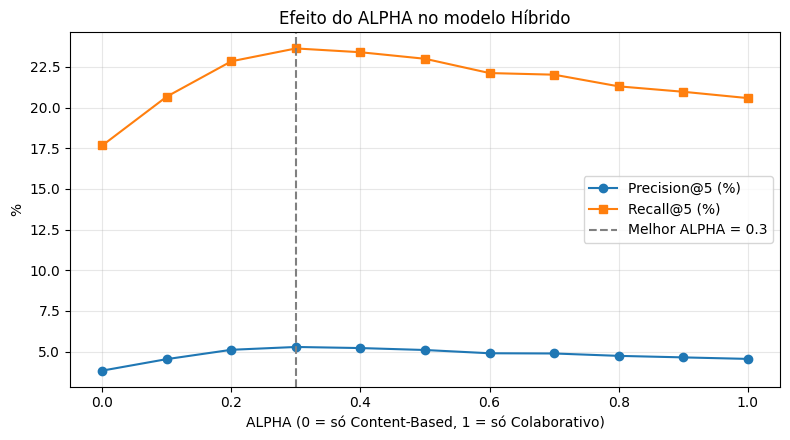

In [11]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(df_alpha["alpha"], df_alpha["precision@5"] * 100, marker="o", label="Precision@5 (%)")
ax.plot(df_alpha["alpha"], df_alpha["recall@5"] * 100, marker="s", label="Recall@5 (%)")
melhor = df_alpha.loc[df_alpha["precision@5"].idxmax(), "alpha"]
ax.axvline(melhor, color="gray", linestyle="--", label=f"Melhor ALPHA = {melhor}")
ax.set_xlabel("ALPHA (0 = só Content-Based, 1 = só Colaborativo)")
ax.set_ylabel("%")
ax.set_title("Efeito do ALPHA no modelo Híbrido")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("grafico_alpha.png", dpi=150)
plt.show()

# 8. Refinamentos: validação separada, n-gramas, vizinhos e NDCG

Na seção 7, o melhor α foi escolhido olhando o próprio conjunto de **teste**. Isso deixa o resultado otimista: é como ajustar a resposta depois de ver o gabarito. Nesta seção o processo passa a ter três partes:

1. **Treino de ajuste e validação.** Dentro do treino de cada usuário, as avaliações mais recentes (últimos 20%) viram uma **validação**. O teste continua guardado.
2. **Busca da configuração na validação.** Testamos, combinados:
   - TF-IDF só com palavras (1-grama) ou com palavras e pares de palavras (1-2 gramas, por exemplo "machine learning");
   - 10, 20 ou 30 vizinhos no KNN;
   - α de 0 a 1.
3. **Avaliação final, uma única vez, no teste**, com a configuração escolhida retreinada no treino completo.

**Novas métricas.** Além de Precision@K e Recall@K, usamos o **NDCG@K**, que dá mais peso aos acertos nas primeiras posições da lista, e medimos com **K = 5 e K = 10**. O critério de escolha na validação é o **NDCG@10**, porque considera a ordem e uma lista um pouco maior.

### 8.1 Funções de apoio: índice dos cursos, treino dos modelos e métricas (incluindo NDCG)

In [12]:
import numpy as np
import pandas as pd
from scipy.sparse import csr_matrix
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.neighbors import NearestNeighbors

# -------------------------------------------------------------
# 1. Um índice único para os cursos (0, 1, 2, ...)
# -------------------------------------------------------------
# Trabalhar com posições numéricas (arrays do numpy) em vez de
# DataFrames deixa a busca de parâmetros bem mais rápida.
cursos8 = courses.drop_duplicates("course_id").reset_index(drop=True)
CURSO_IDX = {c: i for i, c in enumerate(cursos8["course_id"])}
N_CURSOS = len(cursos8)


# -------------------------------------------------------------
# 2. Separar uma VALIDAÇÃO de dentro do treino
# -------------------------------------------------------------
# Mesma regra do split original: para cada usuário, as avaliações
# mais recentes (últimos 20% do TREINO) viram validação.
# O conjunto de TESTE não é tocado até a avaliação final.
def separar_validacao(treino_df):
    t = treino_df.sort_values(["user_id", "date_reviews"]).reset_index(drop=True)
    pos = t.groupby("user_id").cumcount()
    tam = t.groupby("user_id")["user_id"].transform("size")
    corte = (tam * 0.8).astype(int).clip(lower=1)
    return t[pos < corte], t[pos >= corte]


# -------------------------------------------------------------
# 3. "Treinar" os dois modelos com um conjunto qualquer
# -------------------------------------------------------------
def treinar_conteudo(base, ngramas=(1, 1)):
    """TF-IDF sobre o texto das avaliações de cada curso (só da base
    recebida) e similaridade de cosseno entre todos os cursos."""
    texto = base.groupby("course_id")["reviews"].apply(" ".join)
    docs = cursos8["course_id"].map(texto).fillna(cursos8["name"])
    tfidf = TfidfVectorizer(stop_words="english", max_features=5000, min_df=2, ngram_range=ngramas)
    sim = cosine_similarity(tfidf.fit_transform(docs))
    np.fill_diagonal(sim, 0)  # o próprio curso não conta como vizinho
    return sim


def treinar_colaborativo(base, max_vizinhos=30):
    """KNN item-based com distância de cosseno. Guarda, para cada curso,
    os 'max_vizinhos' mais parecidos e a similaridade (1 - distância)."""
    usuarios = base["user_id"].astype("category").cat.codes
    linhas = base["course_id"].map(CURSO_IDX)
    M = csr_matrix((base["rating"].values, (linhas, usuarios)),
                   shape=(N_CURSOS, usuarios.max() + 1))
    knn = NearestNeighbors(metric="cosine", algorithm="brute").fit(M)
    tem_nota = np.asarray(M.getnnz(axis=1)).ravel() > 0
    viz = np.full((N_CURSOS, max_vizinhos), -1)
    sim = np.zeros((N_CURSOS, max_vizinhos))
    idx_com_nota = np.where(tem_nota)[0]
    d, v = knn.kneighbors(M[idx_com_nota], n_neighbors=max_vizinhos + 1)
    for linha, i in enumerate(idx_com_nota):
        outros = [(vv, 1 - dd) for dd, vv in zip(d[linha], v[linha]) if vv != i][:max_vizinhos]
        for k, (vv, s) in enumerate(outros):
            viz[i, k], sim[i, k] = vv, s
    return viz, sim


# -------------------------------------------------------------
# 4. Scores de cada modelo para um usuário (mesma lógica da seção 6)
# -------------------------------------------------------------
def minmax(x, presentes):
    """Normalização 0-1 só entre os cursos que têm score (presentes)."""
    out = np.zeros(N_CURSOS)
    if not presentes.any():
        return out
    a, b = x[presentes].min(), x[presentes].max()
    out[presentes] = 0 if a == b else (x[presentes] - a) / (b - a)
    return out


def scores_usuario(bons, feitos, sim_cb, viz, sim_cf, n_vizinhos):
    """Devolve os scores já normalizados do conteúdo e do colaborativo,
    depois de tirar os cursos que o usuário já fez (ajuste 4 da Etapa 3)."""
    livres = np.ones(N_CURSOS, bool)
    livres[feitos] = False
    cb = sim_cb[:, bons].sum(axis=1)
    cf = np.zeros(N_CURSOS)
    for i in bons:
        v, s = viz[i, :n_vizinhos], sim_cf[i, :n_vizinhos]
        ok = v >= 0
        np.add.at(cf, v[ok], s[ok])
    tem_cf = (cf > 0) & livres
    return minmax(cb, livres), minmax(cf, tem_cf), tem_cf.any()


def combinar(ncb, ncf, tem_cf, alpha):
    # fallback: se o colaborativo não gerou nada, usa só o conteúdo
    return alpha * ncf + (1 - alpha) * ncb if tem_cf else ncb


# -------------------------------------------------------------
# 5. Métricas: Precision@K, Recall@K e NDCG@K
# -------------------------------------------------------------
# NDCG@K (Normalized Discounted Cumulative Gain): além de contar os
# acertos, dá mais peso a quem acerta nas PRIMEIRAS posições.
# Um acerto na posição p vale 1 / log2(p + 1): 1º lugar = 1,0;
# 2º = 0,63; 5º = 0,39. Dividimos pelo melhor valor possível
# (todos os acertos no topo), então o NDCG vai de 0 a 1.
def metricas(recomendados, relevantes, k):
    top = list(recomendados[:k])
    acertos = [1 if c in relevantes else 0 for c in top]
    dcg = sum(a / np.log2(p + 2) for p, a in enumerate(acertos))
    idcg = sum(1 / np.log2(p + 2) for p in range(min(len(relevantes), k)))
    return sum(acertos) / k, sum(acertos) / len(relevantes), dcg / idcg


def top_k(score, feitos, k):
    s = score.copy()
    s[feitos] = -np.inf
    return np.argsort(-s, kind="stable")[:k]


def perfis_usuarios(base):
    """Para cada usuário: cursos avaliados com nota >= 4 (usados para
    recomendar) e todos os cursos já feitos (excluídos da lista)."""
    b = base.assign(i=base["course_id"].map(CURSO_IDX))
    bons = b[b["rating"] >= 4].groupby("user_id")["i"].apply(lambda s: np.unique(s.values))
    feitos = b.groupby("user_id")["i"].apply(lambda s: np.unique(s.values))
    return bons, feitos


def relevantes_de(alvo):
    a = alvo[alvo["rating"] >= 4].assign(i=lambda d: d["course_id"].map(CURSO_IDX))
    return a.groupby("user_id")["i"].apply(set)


def amostrar(relevantes, bons, n=1500, semente=42):
    com_bons = set(bons.index)
    eleg = [u for u in relevantes.index if u in com_bons]
    return pd.Series(eleg).sample(n=min(n, len(eleg)), random_state=semente).tolist()

### 8.2 Busca da melhor configuração na validação

Cada modelo é treinado uma vez por opção (TF-IDF com ou sem pares de palavras; KNN com até 30 vizinhos). O α só muda a soma final, então todas as combinações são avaliadas sobre os mesmos scores. São 1.500 usuários sorteados da validação (semente 42).

In [13]:
import itertools, time

# -------------------------------------------------------------
# 1. Treino de ajuste e validação (o teste fica guardado)
# -------------------------------------------------------------
treino_ajuste, validacao = separar_validacao(treino)
print(f"Treino de ajuste: {len(treino_ajuste):,} avaliações | Validação: {len(validacao):,} avaliações")

bons_aj, feitos_aj = perfis_usuarios(treino_ajuste)
rel_val = relevantes_de(validacao)
usuarios_val = amostrar(rel_val, bons_aj)
print(f"Usuários avaliados na validação: {len(usuarios_val):,}")

# -------------------------------------------------------------
# 2. Opções testadas
# -------------------------------------------------------------
NGRAMAS = {"palavras (1-grama)": (1, 1), "palavras + pares (1-2 gramas)": (1, 2)}
VIZINHOS = [10, 20, 30]
ALPHAS = [round(a, 1) for a in np.arange(0, 1.01, 0.1)]
K_ESCOLHA = 10  # a escolha usa NDCG@10: considera a ordem e uma lista um pouco maior

# Os modelos são treinados uma vez por opção; o alpha só muda a soma final
inicio = time.time()
sim_cb_val = {nome: treinar_conteudo(treino_ajuste, ng) for nome, ng in NGRAMAS.items()}
viz_val, simcf_val = treinar_colaborativo(treino_ajuste, max_vizinhos=max(VIZINHOS))

linhas = []
for nome_ng, n_viz in itertools.product(NGRAMAS, VIZINHOS):
    acum = {a: [] for a in ALPHAS}
    for u in usuarios_val:
        ncb, ncf, tem_cf = scores_usuario(bons_aj[u], feitos_aj[u], sim_cb_val[nome_ng], viz_val, simcf_val, n_viz)
        for a in ALPHAS:
            rec = top_k(combinar(ncb, ncf, tem_cf, a), feitos_aj[u], 10)
            acum[a].append(metricas(rec, rel_val[u], 5) + metricas(rec, rel_val[u], 10))
    for a in ALPHAS:
        m = np.mean(acum[a], axis=0)
        linhas.append({"tfidf": nome_ng, "vizinhos_knn": n_viz, "alpha": a,
                       "precision@5": m[0], "recall@5": m[1], "ndcg@5": m[2],
                       "precision@10": m[3], "recall@10": m[4], "ndcg@10": m[5]})
    print(f"  {nome_ng:<30} {n_viz} vizinhos: ok ({time.time() - inicio:.0f}s)")

df_val = pd.DataFrame(linhas)
df_val.to_csv(DATA_DIR + "busca_validacao.csv", index=False)

# -------------------------------------------------------------
# 3. Melhor configuração NA VALIDAÇÃO
# -------------------------------------------------------------
melhor = df_val.loc[df_val[f"ndcg@{K_ESCOLHA}"].idxmax()]
NGRAMA_FINAL = NGRAMAS[melhor["tfidf"]]
VIZINHOS_FINAL = int(melhor["vizinhos_knn"])
ALPHA_FINAL = float(melhor["alpha"])
print("\nMelhor configuração na validação (critério: NDCG@10):")
print(f"  TF-IDF: {melhor['tfidf']} | vizinhos no KNN: {VIZINHOS_FINAL} | alpha: {ALPHA_FINAL}")

# Resumo: melhor alpha de cada combinação
resumo = (df_val.sort_values("ndcg@10", ascending=False)
          .groupby(["tfidf", "vizinhos_knn"], as_index=False).first()
          .sort_values("ndcg@10", ascending=False))
pd.options.display.float_format = "{:.4f}".format
print("\nMelhor alpha de cada combinação (validação):")
print(resumo[["tfidf", "vizinhos_knn", "alpha", "precision@5", "ndcg@5", "precision@10", "ndcg@10"]].to_string(index=False))

Treino de ajuste: 368,166 avaliações | Validação: 51,675 avaliações


Usuários avaliados na validação: 1,500


  palavras (1-grama)             10 vizinhos: ok (25s)


  palavras (1-grama)             20 vizinhos: ok (27s)


  palavras (1-grama)             30 vizinhos: ok (28s)


  palavras + pares (1-2 gramas)  10 vizinhos: ok (30s)


  palavras + pares (1-2 gramas)  20 vizinhos: ok (31s)


  palavras + pares (1-2 gramas)  30 vizinhos: ok (33s)

Melhor configuração na validação (critério: NDCG@10):
  TF-IDF: palavras (1-grama) | vizinhos no KNN: 30 | alpha: 0.4

Melhor alpha de cada combinação (validação):
                        tfidf  vizinhos_knn  alpha  precision@5  ndcg@5  precision@10  ndcg@10
           palavras (1-grama)            30 0.4000       0.0513  0.1783        0.0339   0.1999
palavras + pares (1-2 gramas)            30 0.5000       0.0520  0.1778        0.0345   0.1995
           palavras (1-grama)            20 0.4000       0.0512  0.1770        0.0340   0.1986
palavras + pares (1-2 gramas)            20 0.4000       0.0519  0.1775        0.0339   0.1981
           palavras (1-grama)            10 0.4000       0.0503  0.1738        0.0343   0.1965
palavras + pares (1-2 gramas)            10 0.4000       0.0513  0.1756        0.0328   0.1937


### 8.3 Avaliação final no teste (uma única vez)

Os modelos são retreinados com o treino completo e avaliados nos mesmos 1.500 usuários de teste da seção 5. Para comparar na mesma régua, a tabela traz também o híbrido da versão 2 (α = 0,3; 1-grama; 10 vizinhos) e o baseline de popularidade por número de avaliações.

In [14]:
# -------------------------------------------------------------
# 1. Retreinar com o TREINO completo, usando a configuração escolhida
# -------------------------------------------------------------
# Também treinamos a configuração da Etapa 3 (v2) para comparar
# as duas na mesma régua.
bons_tr, feitos_tr = perfis_usuarios(treino)
rel_teste = relevantes_de(teste)
usuarios_teste = amostrar(rel_teste, bons_tr)  # mesma regra e semente da seção 5
print(f"Usuários avaliados no teste: {len(usuarios_teste):,}")

sim_cb_v2 = treinar_conteudo(treino, (1, 1))
sim_cb_final = sim_cb_v2 if NGRAMA_FINAL == (1, 1) else treinar_conteudo(treino, NGRAMA_FINAL)
viz_tr, simcf_tr = treinar_colaborativo(treino, max_vizinhos=max(VIZINHOS))

# Baseline: os cursos com mais avaliações no treino
populares = (treino["course_id"].map(CURSO_IDX).value_counts().index.to_numpy())

# -------------------------------------------------------------
# 2. Avaliação ÚNICA no teste
# -------------------------------------------------------------
modelos = {
    "Popularidade (nº de avaliações)": None,
    "Content-Based": ("cb", sim_cb_final, VIZINHOS_FINAL, 0.0),
    "Colaborativo (KNN)": ("cf", sim_cb_final, VIZINHOS_FINAL, 1.0),
    "Híbrido Etapa 3 v2 (alpha 0,3; 1-grama; 10 vizinhos)": ("hib", sim_cb_v2, 10, 0.3),
    f"Híbrido final (alpha {ALPHA_FINAL}; {melhor['tfidf']}; {VIZINHOS_FINAL} vizinhos)": ("hib", sim_cb_final, VIZINHOS_FINAL, ALPHA_FINAL),
}

resultados, por_usuario = [], {}
for nome, cfg in modelos.items():
    vals = []
    for u in usuarios_teste:
        if cfg is None:
            rec = [c for c in populares if c not in set(feitos_tr[u])][:10]
        else:
            tipo, sim_cb, n_viz, a = cfg
            ncb, ncf, tem_cf = scores_usuario(bons_tr[u], feitos_tr[u], sim_cb, viz_tr, simcf_tr, n_viz)
            if tipo == "cf" and not tem_cf:
                rec = []  # sem vizinhos colaborativos: o modelo puro não recomenda nada
            else:
                rec = top_k(ncf if tipo == "cf" else combinar(ncb, ncf, tem_cf, a), feitos_tr[u], 10)
        vals.append(metricas(rec, rel_teste[u], 5) + metricas(rec, rel_teste[u], 10))
    por_usuario[nome] = np.array(vals)
    m = np.mean(vals, axis=0)
    resultados.append({"modelo": nome, "precision@5": m[0], "recall@5": m[1], "ndcg@5": m[2],
                       "precision@10": m[3], "recall@10": m[4], "ndcg@10": m[5]})

df_final = pd.DataFrame(resultados)
df_final.to_csv(DATA_DIR + "resultado_final_etapa3.csv", index=False)
mostrar = df_final.copy()
for c in mostrar.columns[1:]:
    mostrar[c] = (mostrar[c] * 100).map("{:.2f}%".format) if not c.startswith("ndcg") else mostrar[c].map("{:.4f}".format)
print("\nRESULTADO NO TESTE (avaliado uma única vez)")
print(mostrar.to_string(index=False))

Usuários avaliados no teste: 1,500



RESULTADO NO TESTE (avaliado uma única vez)
                                                    modelo precision@5 recall@5 ndcg@5 precision@10 recall@10 ndcg@10
                           Popularidade (nº de avaliações)       2.29%    8.74% 0.0537        1.97%    15.37%  0.0758
                                             Content-Based       3.83%   17.67% 0.1291        2.35%    21.55%  0.1419
                                        Colaborativo (KNN)       4.79%   21.36% 0.1684        3.11%    27.11%  0.1882
      Híbrido Etapa 3 v2 (alpha 0,3; 1-grama; 10 vizinhos)       5.28%   23.63% 0.1817        3.25%    28.75%  0.1990
Híbrido final (alpha 0.4; palavras (1-grama); 30 vizinhos)       5.32%   23.87% 0.1823        3.35%    29.57%  0.2017


### 8.4 A diferença é real? (bootstrap pareado)

Como a diferença entre o híbrido final e o da versão 2 é pequena, verificamos se ela se sustenta ou se pode ser fruto do acaso na amostra de usuários.

In [15]:
# -------------------------------------------------------------
# A diferença entre o híbrido final e o da v2 é real ou acaso?
# -------------------------------------------------------------
# Bootstrap pareado: sorteamos, com reposição, 2.000 novas amostras
# dos MESMOS 1.500 usuários e recalculamos a diferença de cada métrica.
# Se o intervalo de 95% não incluir o zero, a diferença é consistente.
nomes = list(modelos)
final, v2 = por_usuario[nomes[-1]], por_usuario[nomes[-2]]
rng = np.random.default_rng(42)
sorteios = rng.integers(0, len(final), size=(2000, len(final)))
rotulos = ["precision@5", "recall@5", "ndcg@5", "precision@10", "recall@10", "ndcg@10"]
linhas_b = []
for j, nome_m in enumerate(rotulos):
    dif = final[:, j] - v2[:, j]
    boot = dif[sorteios].mean(axis=1)
    baixo, alto = np.percentile(boot, [2.5, 97.5])
    linhas_b.append({"metrica": nome_m, "diferenca_media": dif.mean(), "ic95_inferior": baixo, "ic95_superior": alto,
                     "conclusao": "melhora consistente" if baixo > 0 else ("piora consistente" if alto < 0 else "empate (inclui zero)")})
df_boot = pd.DataFrame(linhas_b)
pd.options.display.float_format = "{:.4f}".format
print("Híbrido final - Híbrido v2 (bootstrap pareado, 2.000 reamostragens):")
print(df_boot.to_string(index=False))

Híbrido final - Híbrido v2 (bootstrap pareado, 2.000 reamostragens):
     metrica  diferenca_media  ic95_inferior  ic95_superior            conclusao
 precision@5           0.0004        -0.0017         0.0027 empate (inclui zero)
    recall@5           0.0024        -0.0074         0.0128 empate (inclui zero)
      ndcg@5           0.0006        -0.0042         0.0058 empate (inclui zero)
precision@10           0.0009        -0.0004         0.0022 empate (inclui zero)
   recall@10           0.0083        -0.0029         0.0191 empate (inclui zero)
     ndcg@10           0.0026        -0.0021         0.0074 empate (inclui zero)


## Conclusão

Resultados no teste (1.500 usuários, avaliação única, seção 8.3):

| Modelo | Precision@5 | Recall@5 | NDCG@5 | Precision@10 | Recall@10 | NDCG@10 |
|---|---|---|---|---|---|---|
| Popularidade (nº de avaliações) | 2,29% | 8,74% | 0,054 | 1,97% | 15,37% | 0,076 |
| Content-Based (TF-IDF) | 3,83% | 17,67% | 0,129 | 2,35% | 21,55% | 0,142 |
| Colaborativo (KNN, 30 vizinhos) | 4,79% | 21,36% | 0,168 | 3,11% | 27,11% | 0,188 |
| Híbrido v2 (α = 0,3; 10 vizinhos) | 5,28% | 23,63% | 0,182 | 3,25% | 28,75% | 0,199 |
| **Híbrido final (α = 0,4; 30 vizinhos)** | **5,32%** | **23,87%** | **0,182** | **3,35%** | **29,57%** | **0,202** |

- O **híbrido** continua sendo o melhor modelo. Contra o baseline de popularidade, acerta cerca de **2,3 vezes mais** entre os 5 primeiros (Precision@5) e tem NDCG@10 **2,7 vezes maior**.
- A configuração escolhida **na validação** (α = 0,4; 30 vizinhos; TF-IDF só com palavras) ficou **empatada** com a da versão 2: o bootstrap pareado mostra que as diferenças estão dentro da variação esperada. O ganho desta versão é de **método**: a escolha deixou de usar o teste.
- **Pares de palavras (1-2 gramas)** no TF-IDF não melhoraram o resultado na validação e não foram adotados.
- **Mais vizinhos no KNN** (30 em vez de 10) ajudaram um pouco na validação e foram adotados.
- O NDCG confirma a mesma ordem dos modelos que a Precision e o Recall: o híbrido acerta mais **e** coloca os acertos mais perto do topo da lista.

Limitações: os usuários são identificados só pelo nome digitado; a base é muito esparsa (0,24% da matriz preenchida); usuários com uma única avaliação não podem ser avaliados (cold-start); os resultados valem para o recorte da Coursera entre 2015 e 2020.